<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Tiwari2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum-kernel SVM for intrusion detection: Tiwari and Kulkarni (2026) step by step

This notebook re-implements, runs and checks the method of

> Anuj Tiwari and Sameer G. Kulkarni, "Leveraging Quantum Kernel Methods for Enhanced Intrusion Detection",
> *2026 18th International Conference on COMmunication Systems and NETworks (COMSNETS), Cybersecurity & Privacy Workshop*,
> pp. 567-572, IEEE, 2026. DOI 10.1109/COMSNETS67989.2026.11418222

The paper publishes no code. Everything below is written from the six-page description, with the software stack the paper
names: PennyLane for the quantum part, scikit-learn for PCA, the classical SVM and the metrics.

**What the notebook does.** It downloads the NSL-KDD dataset (one of the paper's four datasets, and the one that is
public and small enough for a classroom), applies the paper's preprocessing (label encoding of the categorical columns,
median imputation, z-score standardisation, PCA fitted on the training split only), encodes each PCA-reduced connection
with the ZZFeatureMap (`reps = 2`), computes the quantum kernel $K_{ij} = |\langle\Phi(x_i)|\Phi(x_j)\rangle|^2$ and
trains a support-vector machine with that precomputed kernel (QSVM). A classical RBF-kernel SVM, a random forest and a
logistic regression are trained on exactly the same inputs. The kernel-target alignment of the quantum and the RBF kernel
is computed as in Section III.E of the paper, the paper's figures (circuit, confusion matrices, kernel heat-maps) are
redrawn, and the last section puts the paper's Table III (NSL-KDD, PCA = 4 / 8 / 16) next to our numbers with a verdict
per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
a pinned PennyLane; if Colab asks to restart the session, restart and run all again. No GPU and no quantum-cloud account
are needed.

**Runtime.** With `FAST_MODE = True` (4 qubits, 200 connections, the full N^2-circuit kernel route included) the notebook took 4 minutes on the validation machine, a shared laptop CPU; expect 5-10 minutes on a Colab CPU. With `FAST_MODE = False` (4, 8 and 16 qubits, 1,319 connections = 923 training / 396 test, statevector kernel route, 5 repeated draws for the classical baselines) it took 5 minutes on the same machine, of which 3 minutes are the 16-qubit kernel sweep; expect 10-15 minutes on Colab. The committed notebook contains the outputs of the full run.

**What you get at the end.** Accuracy, macro precision, macro recall and macro F1 of the QSVM and of the classical SVM for
every qubit count that was run, the kernel-target alignments, wall-clock times for kernel construction and training, the
paper's figures redrawn from your own run, and a table with one verdict per number the paper reports for NSL-KDD.


## The paper in one page

**Problem.** Decide for each network connection whether it is normal traffic or one of the attack families of the
dataset. The paper evaluates on four benchmark datasets (CICIDS2017, NSL-KDD, CIDDS-001, UGR'16); NSL-KDD is treated as a
multi-class problem (normal plus the DoS, Probe, R2L and U2R attack families), the other three as binary problems.

**Decision.** A support-vector machine. Classically with an RBF kernel; "quantum" with a kernel whose value for two
connections is the fidelity of the two quantum states that encode them.

**Method (Fig. 1 of the paper).** Preprocessing -> PCA to the number of qubits -> ZZFeatureMap (Eq. 3, `reps = 2`) in
PennyLane -> fidelity kernel matrix (Eq. 4) -> classical SVM with a precomputed kernel -> accuracy, precision, recall,
F1, training time. Section III.E adds the kernel-target alignment (Eq. 5-6) as a diagnostic of how well a kernel separates
the classes. All runs are simulated; the paper's server has 128 CPU cores and 256 GB of memory.

**Data (Table I).** NSL-KDD: "147 K samples", features after PCA "6", classes "3 (Probe, DoS, U2R, R2L)". The results
table (Table III) uses PCA = 4, 8 and 16 and reports macro-averaged precision, recall and F1 for the multi-class task.
147 K is the size of the two official files KDDTrain+ (125,973) and KDDTest+ (22,544) together (148,517), so the paper
pooled both files and made its own 70 : 30 stratified split.

**Preprocessing.** Label-encode categorical features; z-score with `StandardScaler`; replace missing values and infinities
with medians; `LabelEncoder` for the class labels; PCA fitted on the training data and applied to the test data.

**Training.** 70 : 30 stratified train-test split, one fixed random seed, classical SVM with an RBF kernel, QSVM =
`SVC(kernel="precomputed")` on the fidelity kernel. No sample size, `C`, `gamma`, PCA whitening, angle range or seed is given.

**Claims for NSL-KDD (Table III, macro averages).**

| PCA dim. (= qubits) | Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| 4 | SVM | 0.785 | 0.790 | 0.768 | 0.779 |
| 4 | QSVM | 0.761 | 0.755 | 0.749 | 0.752 |
| 8 | SVM | 0.810 | 0.805 | 0.798 | 0.801 |
| 8 | QSVM | 0.825 | 0.815 | 0.810 | 0.812 |
| 16 | SVM | 0.820 | 0.812 | 0.805 | 0.808 |
| 16 | QSVM | 0.830 | 0.820 | 0.815 | 0.817 |

Average training time (Table VI, NSL-KDD): SVM about 1 / 3.5 / 10 min and QSVM about 20 min / 1.5 h / 8 h for
PCA = 4 / 8 / 16. The abstract summarises NSL-KDD as "up to 1.5 % higher accuracy and better F1-scores at moderate PCA
dimensions (8-16) but lagged slightly in the lowest-dimensional case". The headline numbers of the abstract (97.1 % vs
94.5 % accuracy, precision 91 % -> 98 %) belong to CIDDS-001 and CICIDS2017, which this notebook does not run.

## What follows the paper and what had to be chosen

The paper fixes the datasets, the preprocessing steps, the feature map, its repetitions, the kernel definition, the split
ratio and the metrics. It does not say how many connections were used (a kernel on 100 K training rows would need
5 x 10^9 circuits, far more than the 20 minutes of Table VI allow), which `C` and `gamma` the SVMs used, what range the
PCA scores had when they entered the circuit, which entanglement pattern the ZZFeatureMap used, or how the three-, four-
or five-class label set was formed. Where the paper is silent this notebook makes a choice and says so in the code (look
for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CICIDS2017, NSL-KDD, CIDDS-001, UGR'16 | NSL-KDD only (public, 4 MB). KDDTrain+ and KDDTest+ pooled as in the paper's "147 K" |
| Classes | Table I: "3 (Probe, DoS, U2R, R2L)"; text: multi-class with macro averages | 5 classes: normal, DoS, Probe, R2L, U2R (`# CHOICE`) |
| Sample size | not given | class-balanced random sample, `N_PER_CLASS` per class (40 in FAST_MODE, 300 otherwise; U2R capped at its 119 rows), `random_state = SEED` |
| Split | 70 : 30 stratified, one seed | same, `SEED = 42` |
| Categorical features | label-encoded | `pd.Categorical` codes with categories fixed on the training split (unseen test values -> -1) |
| Missing values / inf | replaced by medians | `SimpleImputer(strategy="median")` fitted on the training split (NSL-KDD has none) |
| Standardisation | `StandardScaler` | same, fitted on the training split |
| PCA | "2 x number of qubits" in the text, but Fig. 2 and Tables III-V use PCA dim = qubits | one principal component per qubit, `PCA(n_components=N_QUBITS, random_state=SEED)` (`# CHOICE`) |
| Angle range | not given | min-max to [0, pi] on the training split, test clipped; a bandwidth `SCALE` in {0.1, 0.25, 0.5, 1.0} chosen on an inner validation split of the training data (`# CHOICE`) |
| Feature map | "ZZFeatureMap", Eq. 3 (Havlicek et al.), `reps = 2`; prose says "RX rotations followed by RZZ gates" | Eq. 3 as Qiskit defines it: H, RZ(2x_i), ZZ(2(pi-x_j)(pi-x_k)) on neighbouring qubits, `reps = 2`, linear entanglement (`# CHOICE`); the RX variant is available as `FEATURE_MAP = "rx_rzz"` |
| Kernel | fidelity, Eq. 4 | identical; computed twice: once with the adjoint circuit (N^2 circuits, `qml.kernels`), once from statevectors (`|<a|b>|^2`), checked with `np.allclose` |
| Simulator | PennyLane, simulated | PennyLane `default.qubit` for the circuit route, `lightning.qubit` for the statevector route |
| SVM | RBF kernel, `C`/`gamma` not given | two classical SVMs: scikit-learn defaults (`C=1`, `gamma="scale"`) and `C` in {1, 10, 100} x `gamma` in {0.01 ... 3} chosen on the inner validation split; QSVM `SVC(kernel="precomputed")` with `C` and the angle bandwidth chosen the same way (`# CHOICE`) |
| Kernel-target alignment | Eq. 6 with y in {-1, +1} | multi-class form with the one-hot label kernel Y Y^T (`# CHOICE`) |
| Qubit counts | 4, 8, 16 | 4 in FAST_MODE; 4, 8, 16 otherwise |
| Other baselines | none | random forest and logistic regression on the same inputs; RBF-SVM on all 41 features |


## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: 4 qubits, 200 connections, class demo in a few minutes. False: 4/8/16 qubits, about 1,300 connections.
SEED      = 42             # CHOICE: the paper says "the same random seed" but not which one

if FAST_MODE:
    QUBIT_COUNTS       = [4]           # paper: PCA = 4, 8, 16 (one qubit per principal component)
    N_PER_CLASS        = 40            # CHOICE: connections per class (5 classes -> 200 connections, 140 train / 60 test)
    N_BASELINE_REPEATS = 3
else:
    QUBIT_COUNTS       = [4, 8, 16]
    N_PER_CLASS        = 300           # CHOICE: 300 per class, U2R capped at its 119 rows -> 1,319 connections (923 train / 396 test)
    N_BASELINE_REPEATS = 5

CLASSES     = ["normal", "DoS", "Probe", "R2L", "U2R"]   # CHOICE: 5-class task (paper: "3 (Probe, DoS, U2R, R2L)" in Table I)
TEST_SIZE   = 0.30          # paper: 70:30 stratified split
FM_REPS     = 2             # paper: ZZFeatureMap repeated twice
FEATURE_MAP = "zz"          # "zz": Eq. 3 (H, RZ, ZZ) as Qiskit defines it.  "rx_rzz": the paper's prose (RX then RZZ).  CHOICE
ENTANGLEMENT = "linear"     # CHOICE: nearest-neighbour ZZ pairs (Qiskit default is "full"; Fig. 2 of the paper is a 4-qubit chain)
SCALE_GRID  = [0.1, 0.25, 0.5, 1.0]   # CHOICE: angle bandwidth candidates for the quantum kernel, angle = SCALE * minmax(PCA score) * pi
GAMMA_GRID  = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]   # CHOICE: RBF bandwidth candidates for the classical SVM (the paper gives no gamma)
C_GRID      = [1.0, 10.0, 100.0]      # CHOICE: regularisation candidates for both SVMs (the paper gives no C)
VAL_FRACTION = 0.25         # inner validation split of the training data used to pick SCALE / gamma / C (no test data involved)
SVM_C       = 1.0           # the untuned reference SVM: scikit-learn defaults C=1, gamma="scale"
SVM_GAMMA   = "scale"
CIRCUIT_ROUTE_MAX_N = 200   # the N^2-circuit route (qml.kernels) runs in full for the 4-qubit case only if train+test <= this
N_CHECK     = 30            # rows on which the two kernel routes are compared with np.allclose
KERNEL_DEVICE = "default.qubit"    # device for the adjoint-circuit kernel (the paper's route)
STATE_DEVICE  = "lightning.qubit"  # device for the statevector route (falls back to default.qubit)

DATA_DIR = "data"
NSL_KDD_URLS = {   # primary and fallback mirrors of the two official NSL-KDD files
    "KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
    "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"],
}

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

import pennylane as qml
from pennylane import numpy as pnp

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pnp.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200)

import sklearn
print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
try:
    qml.device(STATE_DEVICE, wires=2); print("statevector device:", STATE_DEVICE)
except Exception as e:
    STATE_DEVICE = "default.qubit"; print("lightning.qubit unavailable (%s); statevector device: default.qubit" % type(e).__name__)
print("FAST_MODE =", FAST_MODE, "| qubit counts:", QUBIT_COUNTS, "| connections per class:", N_PER_CLASS)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


statevector device: lightning.qubit
FAST_MODE = False | qubit counts: [4, 8, 16] | connections per class: 300


## 1. The NSL-KDD dataset

NSL-KDD (Tavallaee et al., 2009) is the cleaned-up version of the KDD Cup 1999 data: every row is one TCP/UDP/ICMP
connection described by 41 features (duration, protocol, service, bytes in each direction, login flags, error rates
over the last 100 connections, ...), a label naming the attack type or `normal`, and a difficulty score. The two official
files are `KDDTrain+` (125,973 connections) and `KDDTest+` (22,544 connections, with 17 attack types that never occur in
the training file). The paper reports "147 K samples" and a 70 : 30 stratified split, which only adds up if both files
are pooled, so that is what the cell below does.

The 39 attack names are grouped into the four families the paper lists (DoS, Probe, R2L, U2R) with the standard NSL-KDD
mapping. The files are small (3 MB) and are cached in `DATA_DIR`.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
CAT_COLS = ["protocol_type", "service", "flag"]
FEATURE_COLS = [c for c in COLUMNS if c not in ("label", "difficulty")]

ATTACK_FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    ATTACK_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    ATTACK_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    ATTACK_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    ATTACK_FAMILY[a] = "U2R"

def fetch_nsl_kdd(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        import requests
        for url in NSL_KDD_URLS[name]:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", name, "from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + name + "; set DATA_DIR to a folder that already contains it")
    else:
        print("using cached", path)
    return pd.read_csv(path, header=None, names=COLUMNS)

t0 = time.time()
parts = {name: fetch_nsl_kdd(name) for name in NSL_KDD_URLS}
raw = pd.concat([parts["KDDTrain+.txt"].assign(source="KDDTrain+"), parts["KDDTest+.txt"].assign(source="KDDTest+")],
                ignore_index=True)
raw["family"] = raw["label"].map(ATTACK_FAMILY)
assert raw["family"].notna().all(), "unmapped attack names: %s" % sorted(set(raw.loc[raw["family"].isna(), "label"]))
print(f"loaded in {time.time()-t0:.1f} s: {len(raw):,} connections (paper: 147 K) x {len(FEATURE_COLS)} features")
print("missing values:", int(raw[FEATURE_COLS].isna().sum().sum()), "| infinities:",
      int(np.isinf(raw[FEATURE_COLS].select_dtypes("number")).sum().sum()))
display(pd.crosstab(raw["family"], raw["source"]).loc[CLASSES].assign(total=lambda d: d.sum(axis=1)))
raw[FEATURE_COLS[:8] + ["label", "family"]].head(5)

using cached data\KDDTrain+.txt


using cached data\KDDTest+.txt


loaded in 1.3 s: 148,517 connections (paper: 147 K) x 41 features
missing values: 0 | infinities: 0


source,KDDTest+,KDDTrain+,total
family,,,
normal,9711,67343,77054
DoS,7460,45927,53387
Probe,2421,11656,14077
R2L,2885,995,3880
U2R,67,52,119


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,label,family
0,0,tcp,ftp_data,SF,491,0,0,0,normal,normal
1,0,udp,other,SF,146,0,0,0,normal,normal
2,0,tcp,private,S0,0,0,0,0,neptune,DoS
3,0,tcp,http,SF,232,8153,0,0,normal,normal
4,0,tcp,http,SF,199,420,0,0,normal,normal


## 2. Class-balanced sample and the paper's 70 : 30 split

A fidelity kernel needs one circuit per pair of connections, so the number of connections, not the number of qubits,
decides the simulation time. The paper does not say how many connections it used. We draw `N_PER_CLASS` connections per
class at random (`random_state = SEED`) from the pooled file, which also removes the 650 : 1 imbalance between `normal` and
`U2R` (a class with only 119 connections, so it is capped at that number when `N_PER_CLASS` is larger), and then split
70 : 30 with stratification, exactly the paper's protocol. Every fitted transform in the next
section sees the training part only.

In [5]:
def balanced_draw(seed, n_per_class=N_PER_CLASS):
    # CHOICE: n_per_class rows per class, or all rows of a class if it has fewer (U2R has only 119 rows in the pooled file)
    picks = [raw[raw["family"] == c].sample(n=min(n_per_class, (raw["family"] == c).sum()), random_state=seed)
             for c in CLASSES]
    sample = pd.concat(picks).sample(frac=1.0, random_state=seed)        # shuffle
    X = sample[FEATURE_COLS].reset_index(drop=True)
    y = sample["family"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)

def inner_split(y, seed=SEED):
    """Stratified split of the TRAINING rows into inner-train / inner-validation, used for every hyper-parameter choice."""
    return train_test_split(np.arange(len(y)), test_size=VAL_FRACTION, stratify=y, random_state=seed)

X_train_raw, X_test_raw, y_train, y_test = balanced_draw(SEED)
inner_tr, inner_val = inner_split(y_train)
print(f"training: {len(X_train_raw)} connections, test: {len(X_test_raw)} connections ({int(TEST_SIZE*100)} %)")
print(f"inner validation split of the training rows (for hyper-parameters only): {len(inner_tr)} / {len(inner_val)}")
print("training classes:", dict(zip(CLASSES, np.bincount(y_train, minlength=5).tolist())))
print("test classes    :", dict(zip(CLASSES, np.bincount(y_test, minlength=5).tolist())))

training: 923 connections, test: 396 connections (30 %)
inner validation split of the training rows (for hyper-parameters only): 692 / 231
training classes: {'normal': 210, 'DoS': 210, 'Probe': 210, 'R2L': 210, 'U2R': 83}
test classes    : {'normal': 90, 'DoS': 90, 'Probe': 90, 'R2L': 90, 'U2R': 36}


## 3. Preprocessing: label encoding, median imputation, standardisation, PCA, angles

The paper's Section III.A-B in code. `protocol_type`, `service` and `flag` are text and become integer codes (the
categories are fixed on the training split; a service that only appears in the test split gets the code -1).
Missing values and infinities are replaced by the training medians (NSL-KDD has none, but the step is kept so the
pipeline matches the paper). Every feature is standardised to zero mean and unit variance, then PCA keeps as many
principal components as there are qubits.

One more step is needed that the paper does not mention: the ZZFeatureMap uses its inputs as rotation angles, and a
z-scored principal component can be anywhere between about -10 and +10. We map each component to $[0, \pi]$ with a
min-max scaler fitted on the training split (test values clipped) and multiply by a bandwidth `SCALE` chosen later on a
validation split of the training data. The classical models receive the very same numbers, so the comparison stays fair.

 4 qubits: angles (923, 4) (train) (396, 4) (test) | PCA keeps 48.7% of the variance (first components [0.195 0.133 0.092 0.067])
 8 qubits: angles (923, 8) (train) (396, 8) (test) | PCA keeps 64.7% of the variance (first components [0.195 0.133 0.092 0.067])
16 qubits: angles (923, 16) (train) (396, 16) (test) | PCA keeps 85.5% of the variance (first components [0.195 0.133 0.092 0.067])


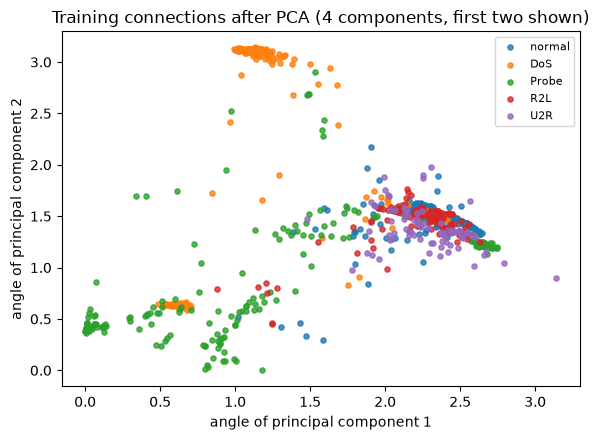

In [6]:
def prepare(X_tr_raw, X_te_raw, n_qubits, seed=SEED):
    """Fit every transform on the training split only. Returns PCA scores mapped to [0, pi] (one per qubit)
    plus the standardised 41-feature matrices for the 'all features' baseline."""
    X_tr, X_te = X_tr_raw.copy(), X_te_raw.copy()
    for c in CAT_COLS:                                   # paper: label encoding of categorical features
        cats = pd.Categorical(X_tr[c]).categories
        X_tr[c] = pd.Categorical(X_tr[c], categories=cats).codes
        X_te[c] = pd.Categorical(X_te[c], categories=cats).codes      # unseen value -> -1
    X_tr = X_tr.astype(float).replace([np.inf, -np.inf], np.nan).to_numpy()
    X_te = X_te.astype(float).replace([np.inf, -np.inf], np.nan).to_numpy()
    imputer = SimpleImputer(strategy="median").fit(X_tr)             # paper: medians for missing values / infinities
    scaler = StandardScaler().fit(imputer.transform(X_tr))            # paper: z-score standardisation
    Z_tr = scaler.transform(imputer.transform(X_tr)); Z_te = scaler.transform(imputer.transform(X_te))
    pca = PCA(n_components=n_qubits, random_state=seed).fit(Z_tr)     # CHOICE: one component per qubit
    P_tr, P_te = pca.transform(Z_tr), pca.transform(Z_te)
    angle = MinMaxScaler((0.0, np.pi)).fit(P_tr)                       # CHOICE: angles in [0, pi], test clipped
    A_tr = angle.transform(P_tr); A_te = np.clip(angle.transform(P_te), 0.0, np.pi)
    return dict(A_train=A_tr, A_test=A_te, Z_train=Z_tr, Z_test=Z_te, pca=pca)

prepared = {n: prepare(X_train_raw, X_test_raw, n) for n in QUBIT_COUNTS}
for n, d in prepared.items():
    ev = d["pca"].explained_variance_ratio_
    print(f"{n:2d} qubits: angles {d['A_train'].shape} (train) {d['A_test'].shape} (test) | "
          f"PCA keeps {ev.sum():.1%} of the variance (first components {np.round(ev[:4], 3)})")

d4 = prepared[QUBIT_COUNTS[0]]
fig, ax = plt.subplots(figsize=(6, 4.5))
for i, c in enumerate(CLASSES):
    m = y_train == i
    ax.scatter(d4["A_train"][m, 0], d4["A_train"][m, 1], s=14, label=c, alpha=0.8)
ax.set_xlabel("angle of principal component 1"); ax.set_ylabel("angle of principal component 2")
ax.set_title(f"Training connections after PCA ({QUBIT_COUNTS[0]} components, first two shown)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Classical baselines on identical inputs

The paper's only baseline is an RBF-kernel SVM on the same PCA-reduced features, with unknown `C` and `gamma`. We train
that SVM twice on **exactly** the angle matrices the quantum kernel will see, for every qubit count: once with
scikit-learn's defaults (`C = 1`, `gamma = "scale"`) and once with `C` and `gamma` chosen on the inner validation split of
the training rows, the same procedure that picks the quantum kernel's bandwidth in Section 7, so that neither kernel gets
a tuning advantage. A random forest and a logistic regression are added as untuned references. To show what PCA costs,
the tuned RBF-SVM is also trained on all 41 standardised features (the paper mentions the "classical SVM's performance on
the complete dataset" for CICIDS2017 but gives no number). All metrics are macro averages over the five classes, as in
the paper's Table III.

A test set of a few hundred connections makes every metric noisy, so the baselines are repeated over
`N_BASELINE_REPEATS` independent balanced draws (draw 0 is the one shared with the QSVM) and reported as mean +- std.

In [7]:
def macro_metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, average="macro", zero_division=0),
                recall=recall_score(y_true, y_pred, average="macro", zero_division=0),
                f1=f1_score(y_true, y_pred, average="macro", zero_division=0))

SVM_DEFAULT, SVM_TUNED = "SVM (rbf, C=1, gamma=scale)", "SVM (rbf, tuned)"

def tune_svm(X, y):
    """CHOICE: pick (C, gamma) by accuracy on the inner validation split of the training rows (ties -> first in grid order)."""
    itr, ival = inner_split(y)
    best = None
    for C in C_GRID:
        for g in GAMMA_GRID:
            acc = accuracy_score(y[ival], SVC(kernel="rbf", C=C, gamma=g).fit(X[itr], y[itr]).predict(X[ival]))
            if best is None or acc > best[0]:
                best = (acc, C, g)
    return SVC(kernel="rbf", C=best[1], gamma=best[2], random_state=SEED), best

def baselines(X, y):
    tuned, (val_acc, C, g) = tune_svm(X, y)
    return {SVM_DEFAULT:          (SVC(kernel="rbf", C=SVM_C, gamma=SVM_GAMMA, random_state=SEED), ""),
            SVM_TUNED:            (tuned, f"C={C:g}, gamma={g:g}, inner-val acc {val_acc:.3f}"),
            "RandomForest":       (RandomForestClassifier(n_estimators=200, random_state=SEED), ""),
            "LogisticRegression": (LogisticRegression(max_iter=3000, random_state=SEED), "")}

baseline_rows, baseline_preds = [], {}
for rep in range(N_BASELINE_REPEATS):
    if rep == 0:
        Xtr_raw, Xte_raw, ytr, yte, prep = X_train_raw, X_test_raw, y_train, y_test, prepared
    else:
        Xtr_raw, Xte_raw, ytr, yte = balanced_draw(SEED + 100 + rep)
        prep = {n: prepare(Xtr_raw, Xte_raw, n) for n in QUBIT_COUNTS}
    for n in QUBIT_COUNTS:
        for mname, (model, chosen) in baselines(prep[n]["A_train"], ytr).items():
            t0 = time.perf_counter(); model.fit(prep[n]["A_train"], ytr); t_fit = time.perf_counter() - t0
            t0 = time.perf_counter(); pred = model.predict(prep[n]["A_test"]); t_pred = time.perf_counter() - t0
            baseline_rows.append(dict(draw=rep, n_qubits=n, model=mname, fit_s=t_fit, predict_s=t_pred, chosen=chosen, **macro_metrics(yte, pred)))
            if rep == 0:
                baseline_preds[(n, mname)] = pred
    Z = prep[QUBIT_COUNTS[0]]                                  # all 41 standardised features, independent of the qubit count
    model, (val_acc, C, g) = tune_svm(Z["Z_train"], ytr)
    t0 = time.perf_counter(); model.fit(Z["Z_train"], ytr); t_fit = time.perf_counter() - t0
    pred = model.predict(Z["Z_test"])
    baseline_rows.append(dict(draw=rep, n_qubits=41, model="SVM (rbf, tuned), all 41 features", fit_s=t_fit, predict_s=0.0,
                              chosen=f"C={C:g}, gamma={g:g}", **macro_metrics(yte, pred)))
baseline_df = pd.DataFrame(baseline_rows)
METRICS = ["accuracy", "precision", "recall", "f1"]
def baseline_row(n, model, draw=0):
    return baseline_df[(baseline_df.draw == draw) & (baseline_df.n_qubits == n) & (baseline_df.model == model)].iloc[0]
print("Draw 0 (the QSVM's own split):")
display(baseline_df[baseline_df.draw == 0].set_index(["n_qubits", "model"])[METRICS + ["fit_s", "chosen"]].round(3))
print(f"Mean +- std over {N_BASELINE_REPEATS} balanced draws:")
display(baseline_df.groupby(["n_qubits", "model"])[METRICS].agg(["mean", "std"]).round(3))

Draw 0 (the QSVM's own split):


accuracy  precision  recall     f1  fit_s                               chosen
n_qubits model                                                                                                            
4        SVM (rbf, C=1, gamma=scale)           0.705      0.764   0.680  0.698  0.029                                     
         SVM (rbf, tuned)                      0.866      0.854   0.842  0.847  0.028  C=100, gamma=3, inner-val acc 0.853
         RandomForest                          0.886      0.884   0.863  0.871  0.809                                     
         LogisticRegression                    0.674      0.716   0.653  0.670  0.061                                     
8        SVM (rbf, C=1, gamma=scale)           0.768      0.813   0.736  0.754  0.026                                     
         SVM (rbf, tuned)                      0.899      0.901   0.871  0.882  0.023   C=10, gamma=1, inner-val acc 0.913
         RandomForest                          0.927      0.929   0.912  0.919  0.784                                     
         LogisticRegression                    0.742      0.792   0.720  0.739  0.134                                     
16       SVM (rbf, C=1, gamma=scale)           0.818      0.854   0.787  0.806  0.036                                     
         SVM (rbf, tuned)                      0.902      0.907   0.870  0.883  0.024   C=10, gamma=1, inner-val acc 0.922
         RandomForest                          0.932      0.933   0.913  0.921  0.978                                     
         LogisticRegression                    0.801      0.835   0.781  0.797  0.171                                     
41       SVM (rbf, tuned), all 41 features     0.909      0.907   0.887  0.894  0.032                     C=10, gamma=0.03

Mean +- std over 5 balanced draws:


accuracy        precision        recall            f1       
                                               mean    std      mean    std   mean    std   mean    std
n_qubits model                                                                                         
4        LogisticRegression                   0.693  0.033     0.728  0.035  0.667  0.043  0.679  0.050
         RandomForest                         0.882  0.014     0.875  0.018  0.869  0.018  0.871  0.017
         SVM (rbf, C=1, gamma=scale)          0.719  0.028     0.772  0.033  0.685  0.041  0.699  0.048
         SVM (rbf, tuned)                     0.862  0.011     0.854  0.011  0.832  0.019  0.839  0.017
8        LogisticRegression                   0.752  0.029     0.790  0.029  0.730  0.028  0.747  0.028
         RandomForest                         0.917  0.010     0.913  0.011  0.905  0.014  0.908  0.011
         SVM (rbf, C=1, gamma=scale)          0.802  0.025     0.840  0.024  0.770  0.031  0.789  0.031
         SVM (rbf, tuned)                     0.896  0.006     0.896  0.010  0.874  0.015  0.882  0.013
16       LogisticRegression                   0.806  0.026     0.836  0.025  0.781  0.027  0.798  0.027
         RandomForest                         0.930  0.011     0.925  0.013  0.919  0.011  0.921  0.010
         SVM (rbf, C=1, gamma=scale)          0.830  0.018     0.862  0.020  0.802  0.021  0.821  0.022
         SVM (rbf, tuned)                     0.904  0.009     0.897  0.011  0.880  0.018  0.886  0.012
41       SVM (rbf, tuned), all 41 features    0.923  0.010     0.911  0.004  0.904  0.015  0.906  0.010

## 5. The ZZFeatureMap in PennyLane (Fig. 2 of the paper)

The paper's Eq. 3 is the feature map of Havlicek et al. (2019) that Qiskit ships as `ZZFeatureMap`:

$$U_{\Phi}(x) = \Big(\exp\big(i \sum_i x_i Z_i + i \sum_{j<k} (\pi - x_j)(\pi - x_k) Z_j Z_k\big)\, H^{\otimes n}\Big)^{\text{reps}}$$

per repetition: a Hadamard on every qubit, a $Z$ rotation by $2x_i$ on qubit $i$, and a $ZZ$ rotation by
$2(\pi - x_j)(\pi - x_k)$ on every entangled pair. PennyLane has no ready-made ZZFeatureMap, so the function below writes
it gate by gate (`qml.IsingZZ(phi)` is $\exp(-i\,\phi\, ZZ/2)$, hence the factor 2). The paper's prose says "RX rotations
followed by RZZ gates", which is not the same circuit as its Eq. 3; set `FEATURE_MAP = "rx_rzz"` to try that reading.
Fig. 2 of the paper shows a 4-qubit chain, so neighbouring qubits are entangled (`ENTANGLEMENT = "linear"`).

The function accepts one sample (a vector) or a whole batch (a matrix): PennyLane's parameter broadcasting then simulates
all samples in one call, which is what makes the statevector route of the next section fast.

0: ──H──RZ(0.14)─╭IsingZZ(14.03)──H───────────────RZ(0.14)─────────────────╭IsingZZ(14.03) ···
1: ──H──RZ(1.71)─╰IsingZZ(14.03)─╭IsingZZ(13.48)──H───────────────RZ(1.71)─╰IsingZZ(14.03) ···
2: ──H──RZ(0.39)─────────────────╰IsingZZ(13.48)─╭IsingZZ(12.54)──H─────────RZ(0.39)────── ···
3: ──H──RZ(2.03)─────────────────────────────────╰IsingZZ(12.54)──H─────────RZ(2.03)────── ···

0: ··· ─────────────────────────────────┤  State
1: ··· ─╭IsingZZ(13.48)─────────────────┤  State
2: ··· ─╰IsingZZ(13.48)─╭IsingZZ(12.54)─┤  State
3: ··· ─────────────────╰IsingZZ(12.54)─┤  State


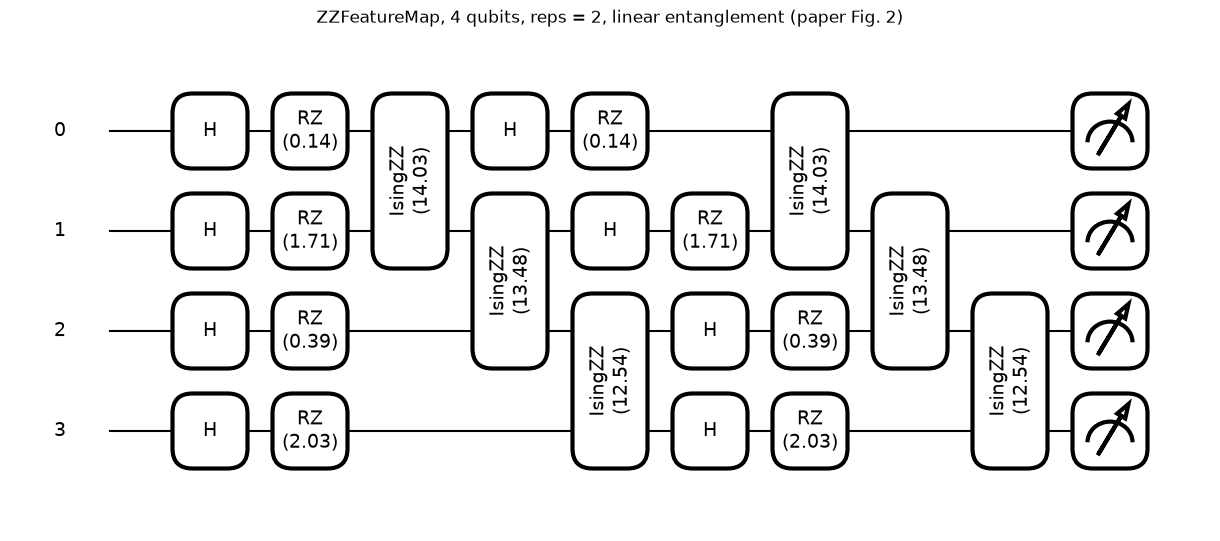

gates per circuit: 22 | depth: 9 | gate types: {'Hadamard': 8, 'RZ': 8, 'IsingZZ': 6}


In [8]:
def zz_feature_map(x, wires, reps=FM_REPS):
    """ZZFeatureMap (paper Eq. 3). x: shape (n,) for one sample or (batch, n) for parameter broadcasting."""
    n = len(wires)
    pairs = [(i, i + 1) for i in range(n - 1)] if ENTANGLEMENT == "linear" else [(i, j) for i in range(n) for j in range(i + 1, n)]
    for _ in range(reps):
        for i in range(n):
            if FEATURE_MAP == "rx_rzz":
                qml.RX(x[..., i], wires=wires[i])                        # the paper's prose: RX rotation by x_i
            else:
                qml.Hadamard(wires=wires[i])
                qml.RZ(2.0 * x[..., i], wires=wires[i])                  # exp(-i x_i Z) = phase gate P(2 x_i) up to a global phase
        for i, j in pairs:
            qml.IsingZZ(2.0 * (np.pi - x[..., i]) * (np.pi - x[..., j]), wires=[wires[i], wires[j]])   # exp(-i (pi-x_i)(pi-x_j) ZZ)

def make_state_qnode(n):
    dev = qml.device(STATE_DEVICE, wires=n)
    @qml.qnode(dev)
    def circuit(x):
        zz_feature_map(x, list(range(n)))
        return qml.state()
    return circuit

def make_kernel_qnode(n):
    """The paper's route: prepare Phi(x1), un-prepare Phi(x2); the probability of |0...0> is |<Phi(x2)|Phi(x1)>|^2."""
    dev = qml.device(KERNEL_DEVICE, wires=n)
    @qml.qnode(dev)
    def circuit(x1, x2):
        zz_feature_map(x1, list(range(n)))
        qml.adjoint(zz_feature_map)(x2, list(range(n)))
        return qml.probs(wires=list(range(n)))
    return lambda x1, x2: circuit(x1, x2)[0]

n0 = QUBIT_COUNTS[0]
state_qnode_demo = make_state_qnode(n0)
x_example = prepared[n0]["A_train"][0]
print(qml.draw(state_qnode_demo, decimals=2)(x_example))
fig, ax = qml.draw_mpl(state_qnode_demo, decimals=2)(x_example)
ax.set_title(f"ZZFeatureMap, {n0} qubits, reps = {FM_REPS}, {ENTANGLEMENT} entanglement (paper Fig. 2)")
plt.show()
specs = qml.specs(state_qnode_demo)(x_example)["resources"]
print("gates per circuit:", specs.num_gates, "| depth:", specs.depth, "| gate types:", dict(specs.gate_types))

## 6. The fidelity kernel, computed two ways

The kernel matrix of Eq. 4, $K_{ij} = |\langle\Phi(x_i)|\Phi(x_j)\rangle|^2$, can be obtained in two ways that give the
same numbers:

* **Circuit route (what the paper describes and what a quantum computer would do).** Run $U_\Phi(x_i)$ followed by
  $U_\Phi(x_j)^\dagger$ and read the probability of measuring all zeros. One circuit per pair: $N(N-1)/2$ circuits for the
  training block (`qml.kernels.square_kernel_matrix`) and $N_{test} \times N_{train}$ for the test block
  (`qml.kernels.kernel_matrix`). On `default.qubit` one 16-qubit circuit costs about 0.3 s, so this route is only
  affordable for a few hundred 4-qubit samples; this is also why the paper's Table VI reports hours.
* **Statevector route (simulator shortcut).** Simulate $|\Phi(x)\rangle$ once per sample (one broadcast call per chunk on
  `lightning.qubit`), then $K = |S_a S_b^\dagger|^2$ with one matrix product. $N$ simulations instead of $N^2$.

The cell below defines both and checks on `N_CHECK` rows that they agree to floating-point precision. The QSVM is then
trained on the statevector kernel; for the 4-qubit case with at most `CIRCUIT_ROUTE_MAX_N` connections the full circuit
route is run as well and timed, so the paper's cost argument can be checked.

In [9]:
def embed_states(state_qnode, A, chunk=64):
    """Statevectors |Phi(x)> for every row of A, as a (len(A), 2^n) complex64 matrix."""
    out = []
    for s in range(0, len(A), chunk):
        block = np.asarray(state_qnode(A[s:s + chunk]))
        out.append(block.reshape(len(A[s:s + chunk]), -1).astype(np.complex64))
    return np.vstack(out)

def fidelity_kernel(SA, SB, chunk=128):
    """K[i, j] = |<Phi(a_i)|Phi(b_j)>|^2 from statevector matrices SA (Na x 2^n) and SB (Nb x 2^n)."""
    K = np.empty((len(SA), len(SB)))
    for s in range(0, len(SA), chunk):
        K[s:s + chunk] = np.abs(SA[s:s + chunk] @ SB.conj().T) ** 2
    return K

# agreement of the two routes on a small block (4 qubits, bandwidth 1)
A_tr0, A_te0 = prepared[n0]["A_train"][:N_CHECK], prepared[n0]["A_test"][:N_CHECK]
kernel_fn = make_kernel_qnode(n0)
t0 = time.perf_counter()
K_circ_train = qml.kernels.square_kernel_matrix(A_tr0, kernel_fn, assume_normalized_kernel=True)
K_circ_test = qml.kernels.kernel_matrix(A_te0, A_tr0, kernel_fn)
t_circ = time.perf_counter() - t0
t0 = time.perf_counter()
S_tr0, S_te0 = embed_states(state_qnode_demo, A_tr0), embed_states(state_qnode_demo, A_te0)
K_sv_train, K_sv_test = fidelity_kernel(S_tr0, S_tr0), fidelity_kernel(S_te0, S_tr0)
t_sv = time.perf_counter() - t0
n_circ = N_CHECK * (N_CHECK - 1) // 2 + N_CHECK * N_CHECK
print(f"circuit route: {n_circ} circuits in {t_circ:.1f} s ({1000*t_circ/n_circ:.1f} ms per circuit) | statevector route: {t_sv:.2f} s")
print("max |difference| train block:", np.abs(K_circ_train - K_sv_train).max(), "| test block:", np.abs(K_circ_test - K_sv_test).max())
assert np.allclose(K_circ_train, K_sv_train, atol=1e-5) and np.allclose(K_circ_test, K_sv_test, atol=1e-5)
print("both routes agree (np.allclose). Diagonal of the training kernel:", np.round(np.diag(K_sv_train)[:5], 6))

circuit route: 1335 circuits in 10.5 s (7.8 ms per circuit) | statevector route: 0.09 s
max |difference| train block: 4.3005830407949475e-07 | test block: 4.597970006958718e-07
both routes agree (np.allclose). Diagonal of the training kernel: [1. 1. 1. 1. 1.]


## 7. Choosing the angle bandwidth on training data only, and kernel-target alignment

With `reps = 2` and angles up to $\pi$ the ZZ terms $(\pi - x_j)(\pi - x_k)$ rotate by up to $2\pi^2$: two connections
that differ a little already have almost orthogonal states, the kernel matrix collapses towards the identity and the SVM
memorises the training set. Shrinking the angles by a factor `SCALE` makes the kernel smoother. The paper does not mention
this (it feeds the PCA scores as they are), so the scale is chosen here by the standard honest procedure, the same one
the classical SVM received in Section 4: the training connections are split once more (75 : 25, stratified), a QSVM is
fitted on the inner training part for every candidate scale and every `C` in `C_GRID`, and the pair with the best
inner-validation accuracy wins. The test split is never touched. Because the kernel does not depend on `C`, each kernel
matrix is computed once per scale and re-used for all `C` values.

The same loop computes the **kernel-target alignment** of Section III.E, Eq. 6,

$$\mathrm{KTA}(K, y) = \frac{\langle K, Y Y^T\rangle_F}{\|K\|_F\,\|Y Y^T\|_F},$$

with $Y$ the one-hot label matrix (so that $Y Y^T$ is 1 for two connections of the same class and 0 otherwise; the
paper's $y y^T$ with $y \in \{-1, +1\}$ is the two-class special case). It is reported for the quantum kernel at every
scale and for the RBF kernel on the same inputs, as the paper's diagnostic of "a potential quantum advantage".

 4 qubits | scale 0.1   | inner-val accuracy C=1: 0.710 C=10: 0.732 C=100: 0.788 | KTA quantum 0.514 (rbf 0.543) | mean off-diagonal kernel value 0.682 | kernel 1.0 s


 4 qubits | scale 0.25  | inner-val accuracy C=1: 0.766 C=10: 0.814 C=100: 0.848 | KTA quantum 0.552 (rbf 0.543) | mean off-diagonal kernel value 0.304 | kernel 1.1 s


 4 qubits | scale 0.5   | inner-val accuracy C=1: 0.792 C=10: 0.835 C=100: 0.840 | KTA quantum 0.556 (rbf 0.543) | mean off-diagonal kernel value 0.234 | kernel 1.0 s


 4 qubits | scale 1.0   | inner-val accuracy C=1: 0.823 C=10: 0.848 C=100: 0.831 | KTA quantum 0.523 (rbf 0.543) | mean off-diagonal kernel value 0.135 | kernel 1.1 s


 8 qubits | scale 0.1   | inner-val accuracy C=1: 0.797 C=10: 0.844 C=100: 0.879 | KTA quantum 0.521 (rbf 0.543) | mean off-diagonal kernel value 0.583 | kernel 2.3 s


...

 8 qubits | scale 1.0   | inner-val accuracy C=1: 0.879 C=10: 0.887 C=100: 0.900 | KTA quantum 0.443 (rbf 0.543) | mean off-diagonal kernel value 0.045 | kernel 2.5 s


16 qubits | scale 0.1   | inner-val accuracy C=1: 0.853 C=10: 0.879 C=100: 0.905 | KTA quantum 0.524 (rbf 0.539) | mean off-diagonal kernel value 0.524 | kernel 62.8 s


16 qubits | scale 0.25  | inner-val accuracy C=1: 0.896 C=10: 0.918 C=100: 0.905 | KTA quantum 0.546 (rbf 0.539) | mean off-diagonal kernel value 0.132 | kernel 39.9 s


16 qubits | scale 0.5   | inner-val accuracy C=1: 0.918 C=10: 0.909 C=100: 0.913 | KTA quantum 0.473 (rbf 0.539) | mean off-diagonal kernel value 0.066 | kernel 30.3 s


16 qubits | scale 1.0   | inner-val accuracy C=1: 0.879 C=10: 0.892 C=100: 0.896 | KTA quantum 0.416 (rbf 0.539) | mean off-diagonal kernel value 0.034 | kernel 33.0 s
chosen (bandwidth, C) per qubit count: {4: (0.25, 100.0), 8: (0.25, 10.0), 16: (0.25, 10.0)}


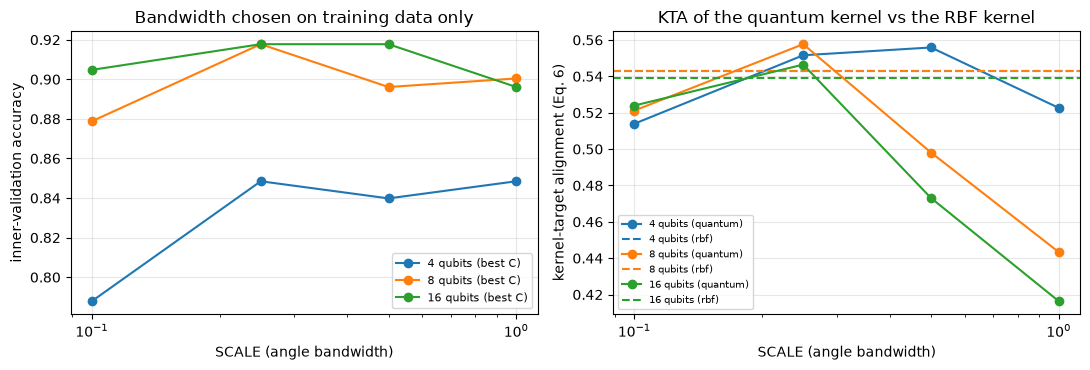

In [10]:
def kta(K, y, n_classes=len(CLASSES)):
    Y = np.eye(n_classes)[y]; T = Y @ Y.T                                    # CHOICE: one-hot label kernel for 5 classes
    return float((K * T).sum() / (np.linalg.norm(K) * np.linalg.norm(T)))

sweep_rows, kernel_cache, state_cache, running_best = [], {}, {}, {}
for n in QUBIT_COUNTS:
    A_tr = prepared[n]["A_train"]; sq = make_state_qnode(n)
    K_rbf = rbf_kernel(A_tr, gamma=1.0 / (A_tr.shape[1] * A_tr.var()))        # sklearn's gamma="scale" on the same inputs
    kta_rbf = kta(K_rbf[np.ix_(inner_tr, inner_tr)], y_train[inner_tr])
    for scale in SCALE_GRID:
        t0 = time.perf_counter()
        S_tr = embed_states(sq, scale * A_tr); K_tr = fidelity_kernel(S_tr, S_tr)
        t_k = time.perf_counter() - t0
        kernel_cache[(n, scale)] = (K_tr, t_k)
        kta_q = kta(K_tr[np.ix_(inner_tr, inner_tr)], y_train[inner_tr])
        best_here = None
        for C in C_GRID:
            svc = SVC(kernel="precomputed", C=C).fit(K_tr[np.ix_(inner_tr, inner_tr)], y_train[inner_tr])
            val_acc = accuracy_score(y_train[inner_val], svc.predict(K_tr[np.ix_(inner_val, inner_tr)]))
            sweep_rows.append(dict(n_qubits=n, scale=scale, C=C, val_accuracy=val_acc, kta_quantum=kta_q, kta_rbf=kta_rbf,
                                   mean_offdiag=float(K_tr[~np.eye(len(K_tr), dtype=bool)].mean()), kernel_seconds=t_k))
            key = (val_acc, kta_q, -C)          # CHOICE: best inner-validation accuracy, ties -> higher KTA, then smaller C
            best_here = key if best_here is None or key > best_here else best_here
        if n not in running_best or best_here > running_best[n][0]:
            running_best[n] = (best_here, scale); state_cache[n] = S_tr      # keep the statevectors of the best scale only
        del S_tr                                                            # (a 16-qubit state matrix is several hundred MB)
        accs = " ".join(f"C={C:g}: {r['val_accuracy']:.3f}" for C, r in zip(C_GRID, sweep_rows[-len(C_GRID):]))
        print(f"{n:2d} qubits | scale {scale:<5} | inner-val accuracy {accs} | KTA quantum {kta_q:.3f} (rbf {kta_rbf:.3f}) | "
              f"mean off-diagonal kernel value {sweep_rows[-1]['mean_offdiag']:.3f} | kernel {t_k:.1f} s")
sweep_df = pd.DataFrame(sweep_rows)
best_scale = {n: float(running_best[n][1]) for n in QUBIT_COUNTS}
best_C = {n: float(-running_best[n][0][2]) for n in QUBIT_COUNTS}
print("chosen (bandwidth, C) per qubit count:", {n: (best_scale[n], best_C[n]) for n in QUBIT_COUNTS})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for n, g in sweep_df.groupby("n_qubits"):
    gb = g.groupby("scale")["val_accuracy"].max()
    axes[0].plot(gb.index, gb.values, "o-", label=f"{n} qubits (best C)")
    g1 = g.drop_duplicates("scale")
    axes[1].plot(g1["scale"], g1["kta_quantum"], "o-", label=f"{n} qubits (quantum)")
    axes[1].axhline(g1["kta_rbf"].iloc[0], ls="--", color=axes[1].lines[-1].get_color(), label=f"{n} qubits (rbf)")
axes[0].set_xscale("log"); axes[0].set_xlabel("SCALE (angle bandwidth)"); axes[0].set_ylabel("inner-validation accuracy")
axes[0].set_title("Bandwidth chosen on training data only"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].set_xscale("log"); axes[1].set_xlabel("SCALE (angle bandwidth)"); axes[1].set_ylabel("kernel-target alignment (Eq. 6)")
axes[1].set_title("KTA of the quantum kernel vs the RBF kernel"); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Training the QSVM for every qubit count

For each qubit count the training kernel at the chosen bandwidth is already in memory; the test block
$K_{test}$ (test x train) is computed the same way and the SVM with the precomputed kernel is trained and evaluated.
Wall-clock times are recorded for the kernel construction (the part that grows quadratically) and for the SVM fit and
prediction separately; the paper's "QSVM training time" is the sum of the first two.

For the 4-qubit case with few enough connections the complete circuit route is run too, so you can see how long the
$N^2$ circuits take compared with the statevector shortcut, and that both give the same predictions.

In [11]:
results = {}
for n in QUBIT_COUNTS:
    scale, C = best_scale[n], best_C[n]; d = prepared[n]; sq = make_state_qnode(n)
    S_tr = state_cache[n]; K_tr, t_ktrain = kernel_cache[(n, scale)]
    t0 = time.perf_counter(); qsvm = SVC(kernel="precomputed", C=C).fit(K_tr, y_train); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); S_te = embed_states(sq, scale * d["A_test"]); K_te = fidelity_kernel(S_te, S_tr); t_ktest = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = qsvm.predict(K_te); t_pred = time.perf_counter() - t0
    train_acc = accuracy_score(y_train, qsvm.predict(K_tr))
    r = dict(n_qubits=n, scale=scale, C=C, kernel_train_s=t_ktrain, fit_s=t_fit, kernel_test_s=t_ktest, predict_s=t_pred,
             train_accuracy=train_acc, n_support=int(qsvm.n_support_.sum()), y_pred=pred, K_train=K_tr, K_test=K_te,
             kta_quantum=kta(K_tr, y_train), kta_rbf=kta(rbf_kernel(d["A_train"], gamma=1.0 / (n * d["A_train"].var())), y_train),
             **macro_metrics(y_test, pred))
    print(f"{n:2d} qubits | scale {scale} C {C:g} | kernel train {t_ktrain:6.1f} s + fit {t_fit:.2f} s | kernel test {t_ktest:5.1f} s | "
          f"train acc {train_acc:.3f} | test acc {r['accuracy']:.3f} P {r['precision']:.3f} R {r['recall']:.3f} F1 {r['f1']:.3f} | "
          f"KTA q {r['kta_quantum']:.3f} rbf {r['kta_rbf']:.3f}")
    if n == 4 and len(y_train) + len(y_test) <= CIRCUIT_ROUTE_MAX_N:
        kf = make_kernel_qnode(n)
        t0 = time.perf_counter(); Kc_tr = qml.kernels.square_kernel_matrix(scale * d["A_train"], kf, assume_normalized_kernel=True); tc1 = time.perf_counter() - t0
        t0 = time.perf_counter(); Kc_te = qml.kernels.kernel_matrix(scale * d["A_test"], scale * d["A_train"], kf); tc2 = time.perf_counter() - t0
        pred_c = SVC(kernel="precomputed", C=C).fit(Kc_tr, y_train).predict(Kc_te)
        r.update(circuit_train_s=tc1, circuit_test_s=tc2, circuit_same_pred=bool((pred_c == pred).all()))
        n_c = len(y_train) * (len(y_train) - 1) // 2 + len(y_test) * len(y_train)
        print(f"   circuit route (paper's N^2 path, {KERNEL_DEVICE}): {n_c} circuits, train block {tc1:.0f} s, test block {tc2:.0f} s, "
              f"kernels agree: {np.allclose(Kc_tr, K_tr, atol=1e-5) and np.allclose(Kc_te, K_te, atol=1e-5)}, same predictions: {r['circuit_same_pred']}")
    results[n] = r

 4 qubits | scale 0.25 C 100 | kernel train    1.1 s + fit 0.04 s | kernel test   0.7 s | train acc 0.892 | test acc 0.856 P 0.856 R 0.820 F1 0.832 | KTA q 0.555 rbf 0.546


 8 qubits | scale 0.25 C 10 | kernel train    2.4 s + fit 0.02 s | kernel test   0.9 s | train acc 0.933 | test acc 0.899 P 0.900 R 0.871 F1 0.882 | KTA q 0.561 rbf 0.548


16 qubits | scale 0.25 C 10 | kernel train   39.9 s + fit 0.01 s | kernel test  15.7 s | train acc 0.952 | test acc 0.899 P 0.901 R 0.871 F1 0.882 | KTA q 0.554 rbf 0.544


## 9. Metrics, confusion matrices and the paper's figures

Table III of the paper, re-computed: accuracy and macro precision / recall / F1 for the classical RBF-SVM and the QSVM on
the same split and inputs. Then the confusion matrices of both models (the paper's Fig. 3 and 4), the RBF and quantum
kernel matrices of the training set sorted by class (Fig. 5), and the paper's Table VI timing comparison in our
numbers.

This notebook's version of Table III (NSL-KDD, macro averages; train_s = kernel + fit):


,pca_dim,model,accuracy,precision,recall,f1,train_s,settings
0,4,"SVM (rbf, C=1, gamma=scale)",0.705,0.764,0.680,0.698,0.029,
1,4,"SVM (rbf, tuned)",0.866,0.854,0.842,0.847,0.028,"C=100, gamma=3, inner-val acc 0.853"
2,4,QSVM,0.856,0.856,0.820,0.832,1.200,"scale=0.25, C=100"
3,8,"SVM (rbf, C=1, gamma=scale)",0.768,0.813,0.736,0.754,0.026,
4,8,"SVM (rbf, tuned)",0.899,0.901,0.871,0.882,0.023,"C=10, gamma=1, inner-val acc 0.913"
5,8,QSVM,0.899,0.900,0.871,0.882,2.400,"scale=0.25, C=10"
6,16,"SVM (rbf, C=1, gamma=scale)",0.818,0.854,0.787,0.806,0.036,
7,16,"SVM (rbf, tuned)",0.902,0.907,0.870,0.883,0.024,"C=10, gamma=1, inner-val acc 0.922"
8,16,QSVM,0.899,0.901,0.871,0.882,39.900,"scale=0.25, C=10"


=== QSVM, 4 qubits, per-class report ===
              precision    recall  f1-score   support

      normal      0.742     0.800     0.770        90
         DoS      0.933     0.933     0.933        90
       Probe      0.942     0.900     0.920        90
         R2L      0.828     0.911     0.868        90
         U2R      0.833     0.556     0.667        36

    accuracy                          0.856       396
   macro avg      0.856     0.820     0.832       396
weighted avg      0.859     0.856     0.854       396

=== QSVM, 8 qubits, per-class report ===
              precision    recall  f1-score   support

      normal      0.826     0.844     0.835        90
         DoS      1.000     0.956     0.977        90
       Probe      0.956     0.967     0.961        90
         R2L      0.830     0.922     0.874        90
         U2R      0.889     0.667     0.762        36

    accuracy                          0.899       396
   macro avg      0.900     0.871     0.882      

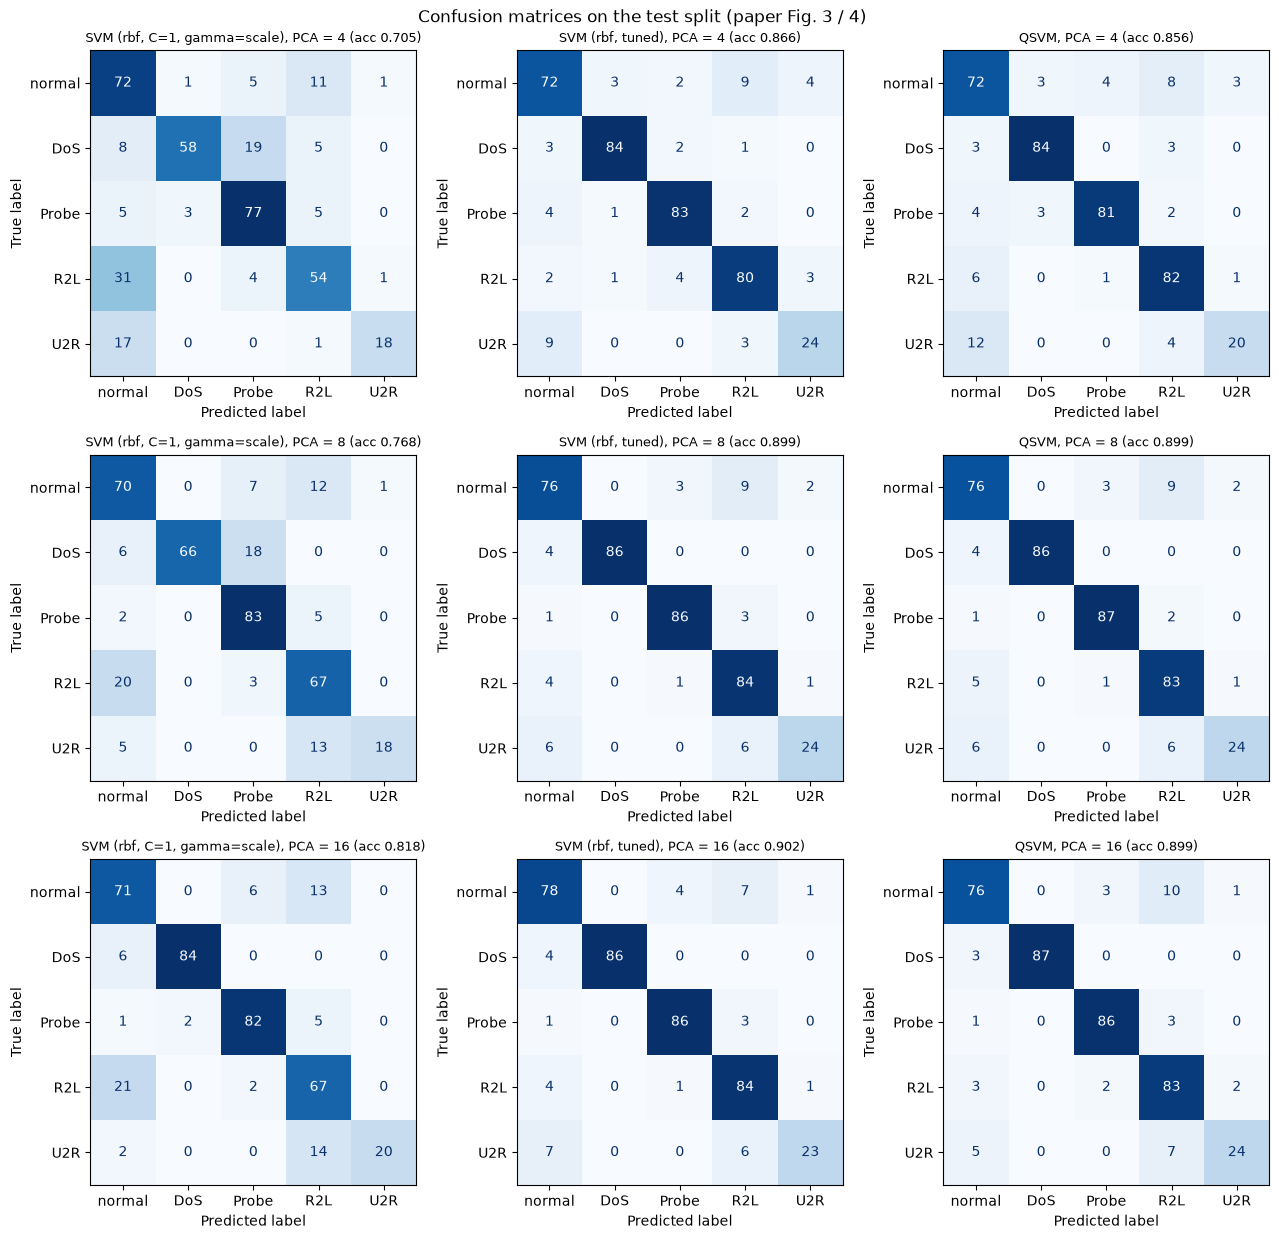

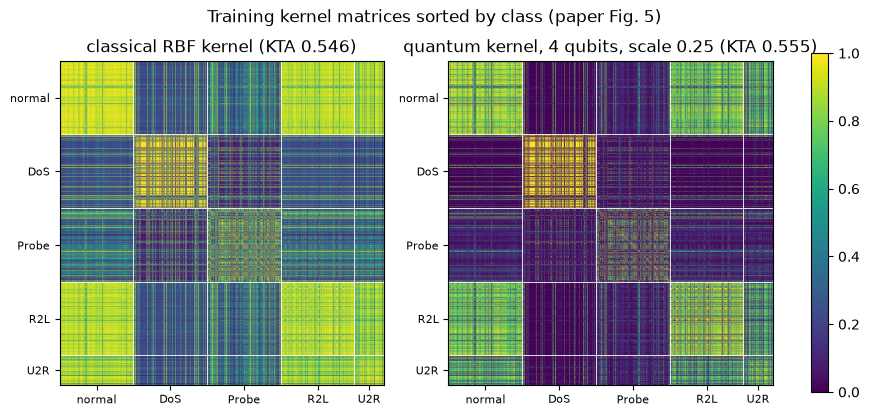

Training time (paper Table VI: NSL-KDD SVM ~1 / 3.5 / 10 min, QSVM ~20 min / 1.5 h / 8 h for PCA 4 / 8 / 16, sample size unknown):


,pca_dim,svm_train_s,qsvm_statevector_train_s,qsvm_circuit_route_train_s,qsvm_test_kernel_s,n_train,n_test
0,4,0.028,1.2,NaN,0.7,923,396
1,8,0.023,2.4,NaN,0.9,923,396
2,16,0.024,39.9,NaN,15.7,923,396


In [12]:
table3 = []
for n in QUBIT_COUNTS:
    for model in (SVM_DEFAULT, SVM_TUNED):
        b = baseline_row(n, model)
        table3.append(dict(pca_dim=n, model=model, **{m: round(b[m], 3) for m in METRICS}, train_s=round(b["fit_s"], 3), settings=b["chosen"]))
    r = results[n]
    table3.append(dict(pca_dim=n, model="QSVM", **{m: round(r[m], 3) for m in METRICS}, train_s=round(r["kernel_train_s"] + r["fit_s"], 1),
                       settings=f"scale={r['scale']:g}, C={r['C']:g}"))
table3 = pd.DataFrame(table3)
print("This notebook's version of Table III (NSL-KDD, macro averages; train_s = kernel + fit):")
display(table3)
for n in QUBIT_COUNTS:
    print(f"=== QSVM, {n} qubits, per-class report ===")
    print(classification_report(y_test, results[n]["y_pred"], labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))

fig, axes = plt.subplots(len(QUBIT_COUNTS), 3, figsize=(13, 4.2 * len(QUBIT_COUNTS)), squeeze=False)
for row, n in enumerate(QUBIT_COUNTS):
    for col, (name, pred) in enumerate([(SVM_DEFAULT, baseline_preds[(n, SVM_DEFAULT)]), (SVM_TUNED, baseline_preds[(n, SVM_TUNED)]),
                                        ("QSVM", results[n]["y_pred"])]):
        cm = confusion_matrix(y_test, pred, labels=range(len(CLASSES)))
        ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=axes[row, col], colorbar=False, cmap="Blues")
        axes[row, col].set_title(f"{name}, PCA = {n} (acc {accuracy_score(y_test, pred):.3f})", fontsize=9)
plt.suptitle("Confusion matrices on the test split (paper Fig. 3 / 4)"); plt.tight_layout(); plt.show()

# paper Fig. 5: RBF kernel vs quantum kernel on the training connections, sorted by class
n = QUBIT_COUNTS[0]; order = np.argsort(y_train, kind="stable"); A_tr = prepared[n]["A_train"]
K_rbf = rbf_kernel(A_tr, gamma=1.0 / (n * A_tr.var()))[np.ix_(order, order)]
K_q = results[n]["K_train"][np.ix_(order, order)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, K, title in [(axes[0], K_rbf, f"classical RBF kernel (KTA {results[n]['kta_rbf']:.3f})"),
                     (axes[1], K_q, f"quantum kernel, {n} qubits, scale {results[n]['scale']} (KTA {results[n]['kta_quantum']:.3f})")]:
    im = ax.imshow(K, cmap="viridis", vmin=0, vmax=1); ax.set_title(title)
    bounds = np.cumsum(np.bincount(y_train, minlength=len(CLASSES)))
    for b in bounds[:-1]:
        ax.axhline(b - 0.5, color="w", lw=0.6); ax.axvline(b - 0.5, color="w", lw=0.6)
    ax.set_xticks(bounds - np.diff(np.r_[0, bounds]) / 2); ax.set_xticklabels(CLASSES, fontsize=8)
    ax.set_yticks(bounds - np.diff(np.r_[0, bounds]) / 2); ax.set_yticklabels(CLASSES, fontsize=8)
fig.colorbar(im, ax=axes, fraction=0.03); plt.suptitle("Training kernel matrices sorted by class (paper Fig. 5)"); plt.show()

# paper Table VI: training time
timing = pd.DataFrame([dict(pca_dim=n, svm_train_s=round(baseline_row(n, SVM_TUNED)["fit_s"], 3),
                            qsvm_statevector_train_s=round(results[n]["kernel_train_s"] + results[n]["fit_s"], 1),
                            qsvm_circuit_route_train_s=round(results[n].get("circuit_train_s", np.nan), 1),
                            qsvm_test_kernel_s=round(results[n]["kernel_test_s"], 1), n_train=len(y_train), n_test=len(y_test))
                       for n in QUBIT_COUNTS])
print("Training time (paper Table VI: NSL-KDD SVM ~1 / 3.5 / 10 min, QSVM ~20 min / 1.5 h / 8 h for PCA 4 / 8 / 16, sample size unknown):")
display(timing)

## 10. Paper versus this notebook

Each row is one number of the paper's Table III for NSL-KDD. The verdict is **reproduced** when our value is within
0.02 of the paper's (two accuracy points, 0.02 in F1 and the other macro metrics), **exceeded** when it is more than 0.02
above, **not reached** when more than 0.02 below, and **not run here** for a qubit count that `FAST_MODE` skipped. The
paper's SVM column is compared with both of our classical SVMs (defaults and tuned). The qualitative claims (which model
is ahead at which PCA dimension) are checked by the sign of the QSVM-minus-tuned-SVM gap on our split, with gaps under
one point called a tie; the timing claims cannot be checked because the paper's hardware and sample size are unknown, so
only our ratio is shown.

In [13]:
PAPER_TABLE3 = {  # NSL-KDD, Table III (macro averages): pca_dim -> model -> (accuracy, precision, recall, f1)
    4:  {"SVM": (0.785, 0.790, 0.768, 0.779), "QSVM": (0.761, 0.755, 0.749, 0.752)},
    8:  {"SVM": (0.810, 0.805, 0.798, 0.801), "QSVM": (0.825, 0.815, 0.810, 0.812)},
    16: {"SVM": (0.820, 0.812, 0.805, 0.808), "QSVM": (0.830, 0.820, 0.815, 0.817)},
}
TOL = 0.02

def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "not run here"
    if abs(ours - paper) <= tol:
        return "reproduced"
    return "exceeded" if ours > paper else "not reached"

rows = []
for dim, models in PAPER_TABLE3.items():
    for model, vals in models.items():
        variants = [("QSVM", results.get(dim))] if model == "QSVM" else \
                   [(SVM_DEFAULT, baseline_row(dim, SVM_DEFAULT) if dim in results else None),
                    (SVM_TUNED, baseline_row(dim, SVM_TUNED) if dim in results else None)]
        for variant, ours in variants:
            for metric, p in zip(METRICS, vals):
                o = None if ours is None else float(ours[metric])
                rows.append(dict(pca_dim=dim, paper_model=model, notebook_model=variant, metric=metric, paper=p,
                                 notebook=None if o is None else round(o, 3), verdict=verdict(p, o)))
comparison = pd.DataFrame(rows)
display(comparison)
print(comparison.groupby("notebook_model")["verdict"].value_counts().to_dict())

# qualitative claims of the abstract / Section V.B (gap of the QSVM over the tuned and over the default SVM)
claims = []
for dim, text in [(4, "QSVM lags behind SVM at PCA = 4 (paper: -2.4 points accuracy)"),
                  (8, "QSVM ahead of SVM at PCA = 8 (paper: +1.5 points accuracy)"),
                  (16, "QSVM ahead of SVM at PCA = 16 (paper: +1.0 point accuracy)")]:
    if dim in results:
        gap_t = results[dim]["accuracy"] - baseline_row(dim, SVM_TUNED)["accuracy"]
        gap_d = results[dim]["accuracy"] - baseline_row(dim, SVM_DEFAULT)["accuracy"]
        paper_sign = -1 if dim == 4 else 1
        v = "tie (within 1 point)" if abs(gap_t) < 0.01 else ("reproduced (same direction)" if np.sign(gap_t) == paper_sign else "not reproduced (opposite direction)")
        claims.append(dict(claim=text, notebook=f"QSVM - tuned SVM = {gap_t:+.3f} (vs default SVM {gap_d:+.3f})", verdict=v + " for the tuned SVM"))
    else:
        claims.append(dict(claim=text, notebook="", verdict="not run here"))
for dim, paper_min in [(4, 20), (8, 90), (16, 480)]:
    if dim in results:
        q = results[dim]["kernel_train_s"] + results[dim]["fit_s"]
        s = baseline_row(dim, SVM_TUNED)["fit_s"]
        extra = f"; circuit route {results[dim]['circuit_train_s']:.0f} s" if "circuit_train_s" in results[dim] else ""
        claims.append(dict(claim=f"Table VI: QSVM training ~{paper_min} min at PCA = {dim}",
                           notebook=f"{q:.1f} s statevector route on {len(y_train)} rows ({q/max(s,1e-9):.0f}x the SVM){extra}",
                           verdict="cannot be checked (hardware and sample size unknown)"))
    else:
        claims.append(dict(claim=f"Table VI: QSVM training ~{paper_min} min at PCA = {dim}", notebook="", verdict="not run here"))
claims.append(dict(claim="Section III.E: higher KTA of the quantum kernel suggests a potential advantage",
                   notebook="; ".join(f"{n}q: KTA quantum {results[n]['kta_quantum']:.3f} vs rbf {results[n]['kta_rbf']:.3f}" for n in QUBIT_COUNTS),
                   verdict="see values (the paper reports no KTA numbers)"))
display(pd.DataFrame(claims))

,pca_dim,paper_model,notebook_model,metric,paper,notebook,verdict
0,4,SVM,"SVM (rbf, C=1, gamma=scale)",accuracy,0.785,0.705,not reached
1,4,SVM,"SVM (rbf, C=1, gamma=scale)",precision,0.790,0.764,not reached
2,4,SVM,"SVM (rbf, C=1, gamma=scale)",recall,0.768,0.680,not reached
3,4,SVM,"SVM (rbf, C=1, gamma=scale)",f1,0.779,0.698,not reached
4,4,SVM,"SVM (rbf, tuned)",accuracy,0.785,0.866,exceeded
5,4,SVM,"SVM (rbf, tuned)",precision,0.790,0.854,exceeded
6,4,SVM,"SVM (rbf, tuned)",recall,0.768,0.842,exceeded
7,4,SVM,"SVM (rbf, tuned)",f1,0.779,0.847,exceeded
8,4,QSVM,QSVM,accuracy,0.761,0.856,exceeded
9,4,QSVM,QSVM,precision,0.755,0.856,exceeded


{('QSVM', 'exceeded'): 12, ('SVM (rbf, C=1, gamma=scale)', 'not reached'): 7, ('SVM (rbf, C=1, gamma=scale)', 'reproduced'): 4, ('SVM (rbf, C=1, gamma=scale)', 'exceeded'): 1, ('SVM (rbf, tuned)', 'exceeded'): 12}


,claim,notebook,verdict
0,QSVM lags behind SVM at PCA = 4 (paper: -2.4 p...,QSVM - tuned SVM = -0.010 (vs default SVM +0.152),reproduced (same direction) for the tuned SVM
1,QSVM ahead of SVM at PCA = 8 (paper: +1.5 poin...,QSVM - tuned SVM = +0.000 (vs default SVM +0.131),tie (within 1 point) for the tuned SVM
2,QSVM ahead of SVM at PCA = 16 (paper: +1.0 poi...,QSVM - tuned SVM = -0.003 (vs default SVM +0.081),tie (within 1 point) for the tuned SVM
3,Table VI: QSVM training ~20 min at PCA = 4,1.2 s statevector route on 923 rows (42x the SVM),cannot be checked (hardware and sample size un...
4,Table VI: QSVM training ~90 min at PCA = 8,2.4 s statevector route on 923 rows (106x the ...,cannot be checked (hardware and sample size un...
5,Table VI: QSVM training ~480 min at PCA = 16,39.9 s statevector route on 923 rows (1673x th...,cannot be checked (hardware and sample size un...
6,Section III.E: higher KTA of the quantum kerne...,4q: KTA quantum 0.555 vs rbf 0.546; 8q: KTA qu...,see values (the paper reports no KTA numbers)


## Reading the paper critically

**The sample size is the missing number.** A fidelity kernel costs one circuit per pair. With the paper's "147 K samples"
and a 70 : 30 split, the training block alone would need about $5 \times 10^9$ circuits; at a millisecond each that is
two months, not the 20 minutes of Table VI. The paper therefore ran on a subsample whose size it never states, and every
accuracy in Table III depends on it (Section 4 above shows the spread between balanced draws of a few hundred rows).
Without that number the paper's results cannot be reproduced exactly, only approached, which is what this notebook does.

**Table I, the text and Table III disagree with each other.** Table I lists NSL-KDD with "6" features after PCA and
"3" classes while naming four attack families; Table III uses PCA = 4, 8, 16; Section III.B says PCA keeps "2 x number of
qubits" features while Fig. 2 pairs PCA = 4 with 4 qubits. The abstract says QSVM "lagged slightly in the lowest-dimensional
case" on NSL-KDD, Section V.B says it "performs better in low-dimensional settings (PCA = 4)", and Table III supports the
abstract (0.761 vs 0.785). In Table II (CICIDS2017) the F1 of 0.916 at PCA = 4 is impossible for a precision of 0.872 and
a recall of 0.719 (the harmonic mean is 0.788). A reader has to decide which statement to trust; this notebook follows the
tables.

**Differences of one or two points on a few hundred test rows are noise.** The paper's NSL-KDD gaps between SVM and QSVM
are 1.0 to 2.4 accuracy points. With $n$ test rows the standard error of an accuracy near 0.8 is
$\sqrt{0.8 \cdot 0.2 / n}$, i.e. about 0.05 for 60 rows and 0.026 for 240 rows; a 95 % interval is twice that. The repeated
draws in Section 4 show the same thing empirically. The paper reports a single seed and no interval, so none of its NSL-KDD
differences is statistically established in either direction.

**Both kernels have a bandwidth, and the paper tunes neither.** Section 7 shows that the angle bandwidth of the quantum
kernel moves the inner-validation accuracy by ten points or more, far more than the SVM-vs-QSVM gaps in the paper, and
Section 4 shows the same for `gamma` and `C` of the RBF kernel (compare the default and the tuned SVM rows). A comparison
in which one kernel happens to sit at a good bandwidth and the other does not is a comparison of settings, not of kernels;
this is why the notebook gives both models the same inner-validation search and reports the untuned SVM separately.
Kernel-target alignment, which the paper proposes as the diagnostic, is exactly the quantity such a sweep could maximise;
the paper computes it but reports no value, and Section 7 shows that it does not even rank the bandwidths in the same
order as the validation accuracy.

**What the full run of this notebook says.** On 1,319 balanced NSL-KDD connections the QSVM and the RBF-SVM, both tuned
on the same inner validation split, end within one accuracy point of each other at every qubit count (Section 9), and
both are 7-11 points above the paper's Table III. The paper's pattern, QSVM clearly ahead at PCA = 8 and 16, appears in
this notebook only when the classical SVM is left at scikit-learn's defaults (`C = 1`, `gamma = "scale"`), where it
trails the QSVM by 8-15 points; the same untuned SVM is also the only configuration whose numbers land near the paper's
SVM column. The simplest reading is that the paper's SVM was not tuned and its QSVM gaps measure that, not the kernel.
Two classical references the paper does not run make the point from the other side: a random forest on the same 4 to 16
principal components reaches 0.88-0.93 accuracy, and a tuned RBF-SVM on all 41 features reaches about 0.91-0.92, above
every PCA-reduced model, quantum or classical.

**The circuit in the text is not the circuit in the equation.** Section III.D describes "RX rotations followed by RZZ
gates", but Eq. 3 and the name ZZFeatureMap denote the Havlicek et al. map with Hadamards and phase rotations. The two give
different kernels (`FEATURE_MAP = "rx_rzz"` lets you try the other reading). The entanglement pattern (full or linear)
is not given either; both affect the kernel and the run time.

**What the timing table really measures.** Table VI compares a classical SVM on 128 cores with a simulated quantum kernel.
On a simulator the quantum kernel is a slow way to compute a classical function; the hours reported say nothing about a
quantum computer, where the cost would instead be dominated by the shots needed per kernel entry (about $1/\epsilon^2$ for
precision $\epsilon$) and by noise. Section 8 shows the same gap on a laptop: the $N^2$ circuit route is orders of magnitude
slower than the statevector shortcut, which gives bit-for-bit the same kernel.

## Exercises

1. **Bandwidth.** Set `SCALE_GRID = [1.0]` to use the PCA scores as raw angles, as the paper's text implies. How does the
   training accuracy, the test accuracy and the mean off-diagonal kernel value change? Explain the result with the
   kernel heat-map of Section 9.
2. **The other reading of the feature map.** Set `FEATURE_MAP = "rx_rzz"` and `ENTANGLEMENT = "full"` and rerun. Does the
   KTA or the accuracy change more than the seed-to-seed spread of Section 4?
3. **Binary task.** Change `CLASSES` handling so that all four attack families become one `attack` class (binary normal vs
   attack, as the paper does for its other three datasets). Which metric changes most, and why does macro-averaging
   over five classes punish the rare `U2R` class?
4. **Sample size.** Double `N_PER_CLASS` (with `FAST_MODE = False`). How do the kernel times in Section 8 scale, and
   does the SVM-vs-QSVM gap move outside the noise band?
5. **Statistical honesty.** Repeat the QSVM over the `N_BASELINE_REPEATS` balanced draws (the baselines already are) and
   report mean +- std. Is the paper's 1.5-point claim distinguishable from zero?
6. **Shots.** Replace `qml.probs` in `make_kernel_qnode` by a finite-shot estimate (`qml.device("default.qubit", wires=n,
   shots=1000)`) and look at the kernel matrix: it is no longer exactly positive semi-definite. What does scikit-learn do
   with it, and what does the literature propose (e.g. clipping negative eigenvalues)?